## Imports

In [ ]:
import numpy as np
import torch
import torchvision.transforms.functional as F
from pathlib import Path
import sys
# Add project directories so local modules import correctly
repo_root = Path.cwd()
for p in (repo_root / "04_modeling", repo_root / "03_datapreparation"):
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.append(p_str)
# Models
from models.unet import UNet
from models.deeplab import DeepLabV3Plus
from models.segformer import SegFormer
# Dataset, DataLoader and Transforms
from cityscapes_dataset import CityscapesDataset
from torch.utils.data import DataLoader
from PIL import Image
# For visualization
import matplotlib.pyplot as plt
import cv2

## Visualisierung
- Color Arrays
- LabelId in RGB-Farbe umwandeln mit `label_to_color()`
- Checkpoint visualisieren mit `visualize_checkpoint()`

In [2]:
# Cityscapes 18 class colors (R,G,B) based on old trainIds
CITYSCAPES_COLORS_18 = np.array([
    [128, 64,128],  # 0: road
    [244, 35,232],  # 1: sidewalk
    [230,150,140],  # 2: rail track
    [ 70, 70, 70],  # 3: building
    [180,165,180],  # 4: guard rail
    [153,153,153],  # 5: pole
    [250,170, 30],  # 6: traffic light
    [220,220,  0],  # 7: traffic sign
    [152,251,152],  # 8: terrain
    [ 70,130,180],  # 9: sky
    [220, 20, 60],  # 10: person
    [255,  0,  0],  # 11: rider
    [  0,  0,142],  # 12: car
    [  0,  0, 70],  # 13: truck
    [  0, 60,100],  # 14: bus
    [  0, 80,100],  # 15: train
    [  0,  0,230],  # 16: motorcycle
    [119, 11, 32],  # 17: bicycle
], dtype=np.uint8)

# Cityscapes 20 class colors (R,G,B) based on current trainIds (added vegetation and parking classes)
CITYSCAPES_COLORS_20 = np.array([
    [128, 64,128],  # 0: road
    [244, 35,232],  # 1: sidewalk
    [250,170,160],  # 2: parking
    [230,150,140],  # 3: rail track
    [ 70, 70, 70],  # 4: building
    [180,165,180],  # 5: guard rail
    [153,153,153],  # 6: pole
    [250,170, 30],  # 7: traffic light
    [220,220,  0],  # 8: traffic sign
    [107,142, 35],  # 9: vegetation
    [152,251,152],  # 10: terrain
    [ 70,130,180],  # 11: sky
    [220, 20, 60],  # 12: person
    [255,  0,  0],  # 13: rider
    [  0,  0,142],  # 14: car
    [  0,  0, 70],  # 15: truck
    [  0, 60,100],  # 16: bus
    [  0, 80,100],  # 17: train
    [  0,  0,230],  # 18: motorcycle
    [119, 11, 32],  # 19: bicycle
], dtype=np.uint8)

def label_to_color(label, color_array):
    h, w = label.shape
    color_image = np.zeros((h, w, 3), dtype=np.uint8)
    for class_idx, color in enumerate(color_array):
        mask = label == class_idx
        color_image[mask] = color

    # Set ignore_index to black
    mask = label == 255
    color_image[mask] = [0, 0, 0]
    return color_image

def build_model(model_name, num_classes, backbone="b0"):
    name = model_name.lower()
    if name == "unet":
        return UNet(num_classes)
    if name == "deeplab":
        return DeepLabV3Plus(num_classes)
    if name == "segformer":
        return SegFormer(num_classes, phi=backbone)
    raise ValueError(f"Unsupported model: {model_name}")

In [3]:
def visualize_checkpoint(model_name, checkpoint_name, color_array, num_classes):
    checkpoint = torch.load(f"./checkpoints/{checkpoint_name}/best_{checkpoint_name}.pth", weights_only=False)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = build_model(model_name, num_classes)
    model_name = getattr(model, "name")
    model = model.to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    print(f"Model: {model_name}")
    print(f"Epoch: {checkpoint['epoch']}")
    print(f"Train Loss: {checkpoint['train_loss']}")
    print(f"Train Accuracy: {checkpoint['train_acc']}")
    print(f"Train MIoU: {checkpoint['train_miou']}")
    print(f"Val Loss: {checkpoint['val_loss']}")
    print(f"Val Accuracy: {checkpoint['val_acc']}")
    print(f"Val MIoU: {checkpoint['val_miou']}")

    # Transforms
    height, width = 512, 1024
    def image_transform(image):
        image = Image.fromarray(image)  # numpy -> PIL
        image = F.resize(image, (height, width), interpolation=F.InterpolationMode.BILINEAR) # Bilinear for RGB-Images
        image = F.pil_to_tensor(image).float() / 255.0  # Scaling
        return image


    def label_transform(label):
        label = Image.fromarray(label)  # numpy -> PIL
        label = F.resize(label, (height, width), interpolation=F.InterpolationMode.NEAREST) # Nearest Neighbor for Labels
        label = F.pil_to_tensor(label).long().squeeze()  # PIL -> LongTensor no Scaling, squeeze() to remove channel dimension
        return label


    # Define data paths
    data_dir = Path("./data/cityscapes_intersections_heading/fine_intersections_3")
    image_dir = data_dir / "leftImg8bit_trainvaltest/leftImg8bit"
    label_dir = data_dir / "gtFine_trainvaltest/gtFine"

    # Initialize datasets
    train_dataset = CityscapesDataset(image_dir, label_dir, split="train", image_transform=image_transform, label_transform=label_transform)
    val_dataset = CityscapesDataset(image_dir, label_dir, split="val", image_transform=image_transform, label_transform=label_transform)

    fig, axes = plt.subplots(1, 3, figsize=(20, 10))

    with torch.no_grad():
        image, label = train_dataset[6]
        image = image.unsqueeze(0)
        image = image.to(device)

        prediction = model(image)
        prediction = prediction.squeeze(0)
        predicted = torch.argmax(prediction, dim=0).cpu().numpy()
        
    axes[0].imshow(image.squeeze(0).cpu().permute(1, 2, 0))
    axes[0].set_title("Original image")
    axes[0].axis("off")
    axes[1].imshow(label_to_color(label, CITYSCAPES_COLORS_20))
    axes[1].set_title("Ground truth")
    axes[1].axis("off")
    axes[2].imshow(label_to_color(predicted, color_array))
    axes[2].set_title("Predicted")
    axes[2].axis("off")
    plt.show()

## Warum Vegetation als lernbare Klasse wichtig ist

Das Hinzufügen der Klasse **Vegetation** verbessert die Segmentierung von Verkehrsschildern und Ampeln erheblich. 

Problem ohne Vegetation-Klasse:
- Verkehrsschilder und Ampeln befinden sich häufig vor Bäumen und Büschen
- Ohne explizite Vegetation-Klasse lernt das Modell die Klassengrenzen unscharf
- Overlap-Bereiche werden falsch klassifiziert

Mit Vegetation-Klasse:
- Das Modell lernt klare Abgrenzungen zwischen Vegetation und darüber liegenden Objekten
- Bessere Erkennung von Verkehrsschildern und Ampeln im Kontext von Grünflächen 
- Reduzierung von Fehlklassifikationen an Objektgrenzen

Die Visualisierung zeigt deutlich: Mit Vegetation (aktuell, 20 Klassen) werden Verkehrsschilder und Ampeln präziser segmentiert als ohne (alt, 18 Klassen).

-> Ausschlaggebend für die Extraktion von korrekten Kennzahlen

Model: deeplabv3plus
Epoch: 446
Train Loss: 0.020955644610027472
Train Accuracy: 0.9852903366088868
Train MIoU: 0.8648541825216225
Val Loss: 0.18158172319332758
Val Accuracy: 0.9407072762648264
Val MIoU: 0.5370953758927607


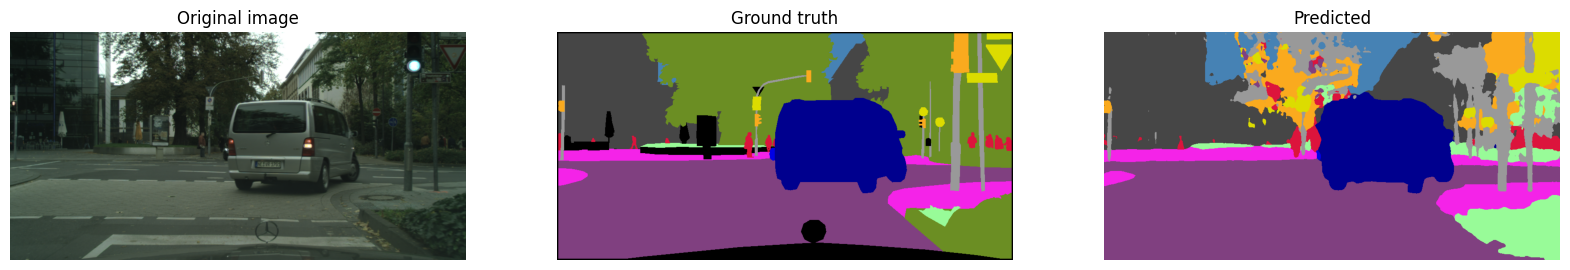

In [4]:
# Alte 18 Klassen
visualize_checkpoint("deeplab", "deeplab_cityscapes_3244895", CITYSCAPES_COLORS_18, 18)

Model: deeplabv3plus
Epoch: 199
Train Loss: 0.06996467659870784
Train Accuracy: 0.9596164226531982
Train MIoU: 0.6942357507803419
Val Loss: 0.15436224887768427
Val Accuracy: 0.9292846322059631
Val MIoU: 0.5089366528013779


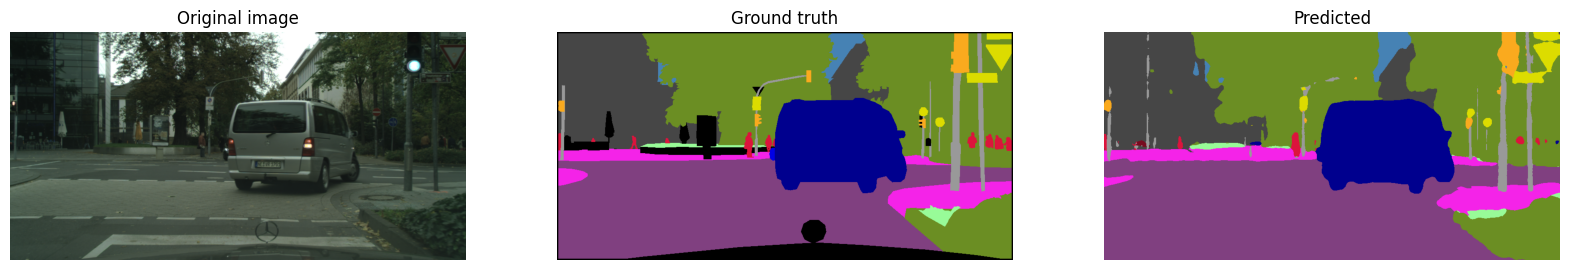

In [5]:
# Neue 20 Klassen (Vegetation und Parking hinzugefügt)
visualize_checkpoint("deeplab", "deeplab_cityscapes_3258105", CITYSCAPES_COLORS_20, 20)

In [16]:
def visualize_cvat_images(model_name, checkpoint_name, color_array=CITYSCAPES_COLORS_20, num_classes=20):
    checkpoint = torch.load(f"./checkpoints/{checkpoint_name}/best_{checkpoint_name}.pth", weights_only=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = build_model(model_name, num_classes)
    model_name = getattr(model, "name")
    model = model.to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    
    print(f"Model: {model_name}")
    print(f"Epoch: {checkpoint['epoch']}")
    print(f"Train Loss: {checkpoint['train_loss']}")
    print(f"Train Accuracy: {checkpoint['train_acc']}")
    print(f"Train MIoU: {checkpoint['train_miou']}")
    print(f"Val Loss: {checkpoint['val_loss']}")
    print(f"Val Accuracy: {checkpoint['val_acc']}")
    print(f"Val MIoU: {checkpoint['val_miou']}")

    cvat_path = "./05_evaluation/CVATAnnotations"
    cvat_dir = Path(cvat_path)
    label_paths = [f for f in cvat_dir.glob("bild*.png") if not f.stem.endswith("r")]

    for label_path in label_paths:
        # RGB-Label laden
        mask = cv2.imread(str(label_path))
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

        # Original laden (bild1.png -> bild1r.jpg)
        image_path = label_path.parent / f"{label_path.stem}r.jpg"
        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Transforms 
        height, width = 768, 1024 # Original 1536, 2048

        def image_transform(image):
            image = Image.fromarray(image)  # numpy -> PIL
            image = F.resize(image, (height, width), interpolation=F.InterpolationMode.BILINEAR) # Bilinear for RGB-Images
            image = F.pil_to_tensor(image).float() / 255.0  # Scaling
            return image
        
        def label_transform(label):
            label = Image.fromarray(label)  # numpy -> PIL
            label = F.resize(label, (height, width), interpolation=F.InterpolationMode.NEAREST) # Nearest Neighbor for Labels
            label = F.pil_to_tensor(label).long().squeeze()  # PIL -> LongTensor no Scaling, squeeze() to remove channel dimension
            return label

        with torch.no_grad():
            image = image_transform(image)
            image = image.unsqueeze(0)
            image = image.to(device)

            prediction = model(image)
            prediction = prediction.squeeze(0)
            predicted = torch.argmax(prediction, dim=0).cpu().numpy()

        # Visualisierung
        fig, axes = plt.subplots(1, 3, figsize=(12, 6))

        image = image.squeeze(0).cpu().permute(1, 2, 0)
        axes[0].imshow(image)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        mask = label_transform(mask)
        mask = mask.permute(1, 2, 0)
        axes[1].imshow(mask)
        axes[1].set_title("Ground Truth")
        axes[1].axis('off')

        axes[2].imshow(label_to_color(predicted, color_array))
        axes[2].set_title("Predicted")
        axes[2].axis('off')
        plt.show()

Model: deeplabv3plus
Epoch: 199
Train Loss: 0.06996467659870784
Train Accuracy: 0.9596164226531982
Train MIoU: 0.6942357507803419
Val Loss: 0.15436224887768427
Val Accuracy: 0.9292846322059631
Val MIoU: 0.5089366528013779


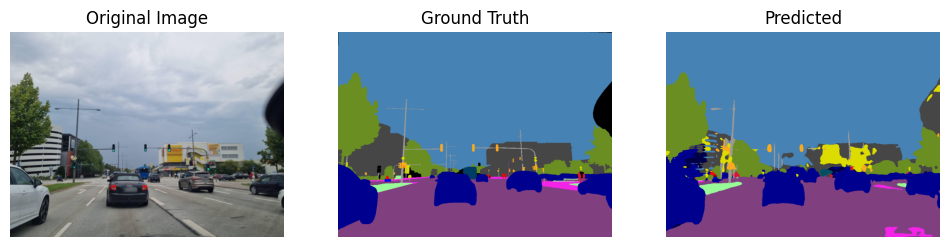

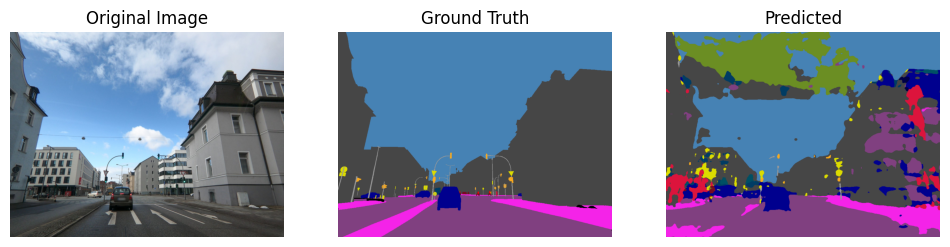

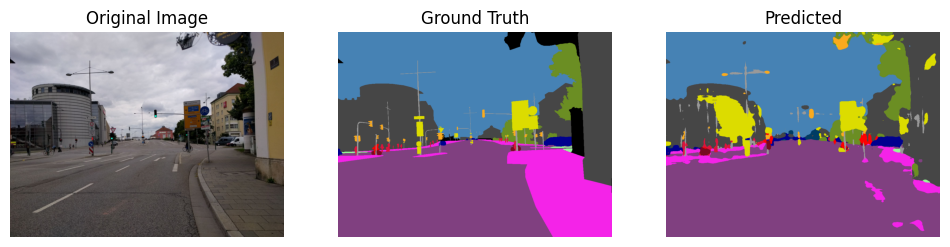

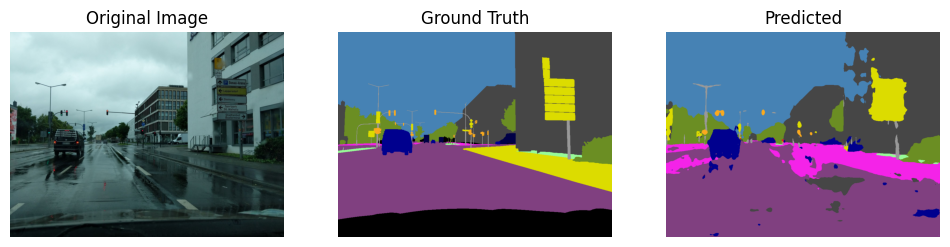

In [18]:
visualize_cvat_images("deeplab", "deeplab_cityscapes_3258105")